# Análise Exploratória Inicial — LIAR (agrupamento Sentimental LIAR)
## Objetivo
Analisar os textos do LIAR com o agrupamento binário de Sentimental LIAR, preservando as partições originais. Esta versão usa os TSV originais do LIAR, não os atributos adicionais de sentimento e emoção do corpus estendido.

## Declaração de uso de Inteligência Artificial
O código e descrição foram adaptados com auxílio de IA (ChatGPT, OpenAI).

## Etapas
- Carregamento automático dos TSV originais.
- Transformação das seis classes em duas, sem descartar registros.
- Distribuição absoluta e percentual por partição.
- Pré-processamento textual conforme EDA original, preservando a afirmação original.
- Nuvens de palavras por classe e partição, em tons de cinza, exportadas em JPG a 300 dpi.

## Considerações
Este notebook possui finalidade apenas de estudo e experimentação. As nuvens representam frequências, não capacidade discriminativa. Half-true é agrupado em False por convenção experimental.

## Referências
- Wang (2017). [LIAR](https://aclanthology.org/P17-2067/).
- Upadhayay e Behzadan (2020). [Sentimental LIAR](https://arxiv.org/abs/2009.01047).


# Implementação

In [1]:
%pip install -q pandas matplotlib nltk wordcloud requests

## 1. INSTALAÇÃO E IMPORTAÇÕES

In [2]:
import re
from collections import Counter
import matplotlib.pyplot as plt
import nltk
import pandas as pd
import requests

from nltk.corpus import stopwords
from wordcloud import WordCloud
nltk.download("stopwords", quiet=True)
import io
import zipfile
import requests
from pathlib import Path

SEED = 42
STOPWORDS = set(stopwords.words("english"))

LIAR_URL = "https://www.cs.ucsb.edu/~william/data/liar_dataset.zip"
OUTPUT_DIR = Path("figures_senti")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


## 2. DEFINIÇÃO DAS CLASSES

In [3]:
LIAR_CLASSES = {"pants-fire": 0, "false": 0, "barely-true": 0, "half-true": 0, "mostly-true": 1, "true": 1}
CLASS_NAMES = {"senti": {0: "False", 1: "True"}}
DATASET_MAPS = {"senti": LIAR_CLASSES}
CLASS_GRAY_COLORS = {"senti": {0: "#252525", 1: "#737373"}}

## 3. CARREGAMENTO DO LIAR — ARQUIVOS ORIGINAIS

In [4]:
def load_liar():
    response = requests.get(LIAR_URL, timeout=120)
    response.raise_for_status()
    files = {"train": "train.tsv", "validation": "valid.tsv", "test": "test.tsv",}
    splits = {}

    with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
        for split, filename in files.items():
            path = next(
                name for name in archive.namelist()
                if name.endswith(filename)
            )
            with archive.open(path) as file:
                df = pd.read_csv(
                    file,
                    sep="\t",
                    header=None,
                    dtype=str,
                )
            # Coluna 1: rótulo; coluna 2: afirmação.
            df = df.iloc[:, [2, 1]].copy()
            df.columns = ["statement", "original_label"]
            df["original_label"] = (
                df["original_label"]
                .str.strip()
                .str.lower()
            )
            df["partition"] = split
            splits[split] = df.reset_index(drop=True)
    return splits

splits = load_liar()
print("LIAR carregado com sucesso!")
for split, df in splits.items():
    print(f"{split}: {len(df)} registros")

LIAR carregado com sucesso!
train: 10240 registros
validation: 1284 registros
test: 1267 registros


## 4. TRANSFORMAÇÃO DOS DATASETS

In [5]:
def create_label_columns(df):
    """Adiciona os rótulos numéricos ao mesmo texto."""
    result = df.copy()
    # Normaliza nomes, sem alterar os textos originais.
    names = (
        result["original_label"]
        .str.lower()
        .str.strip()
        .str.replace("_", "-", regex=False)
    )
    for dataset, mapping in DATASET_MAPS.items():
        result[dataset] = names.map(mapping)
        if result[dataset].isna().any():
            unknown = names[result[dataset].isna()].unique()
            raise ValueError(
                f"Rótulos não reconhecidos em {dataset}: {unknown}"
            )
        result[dataset] = result[dataset].astype(int)
    return result

splits = {
    name: create_label_columns(df)
    for name, df in splits.items()
}

df_senti = pd.concat(splits.values(), ignore_index=True)
print(df_senti.groupby("original_label").size())
print(df_senti[["partition", "statement", "original_label", "senti"]].head().to_string(index=False))

print(pd.crosstab(df_senti["original_label"], df_senti["partition"]))
assert len(df_senti) == sum(len(df) for df in splits.values())

original_label
barely-true    2103
false          2507
half-true      2627
mostly-true    2454
pants-fire     1047
true           2053
dtype: int64
partition                                                                                                                                     statement original_label  senti
    train                                                            Says the Annies List political group supports third-trimester abortions on demand.          false      0
    train When did the decline of coal start? It started when natural gas took off that started to begin in (President George W.) Bushs administration.      half-true      0
    train                                     Hillary Clinton agrees with John McCain "by voting to give George Bush the benefit of the doubt on Iran."    mostly-true      1
    train                                                                Health care reform legislation is likely to mandate free sex change surgeries.     

## 5. DISTRIBUIÇÃO E BALANCEAMENTO DAS CLASSES

            Fake  True
Train       6602  3638
Validation   864   420
Test         818   449


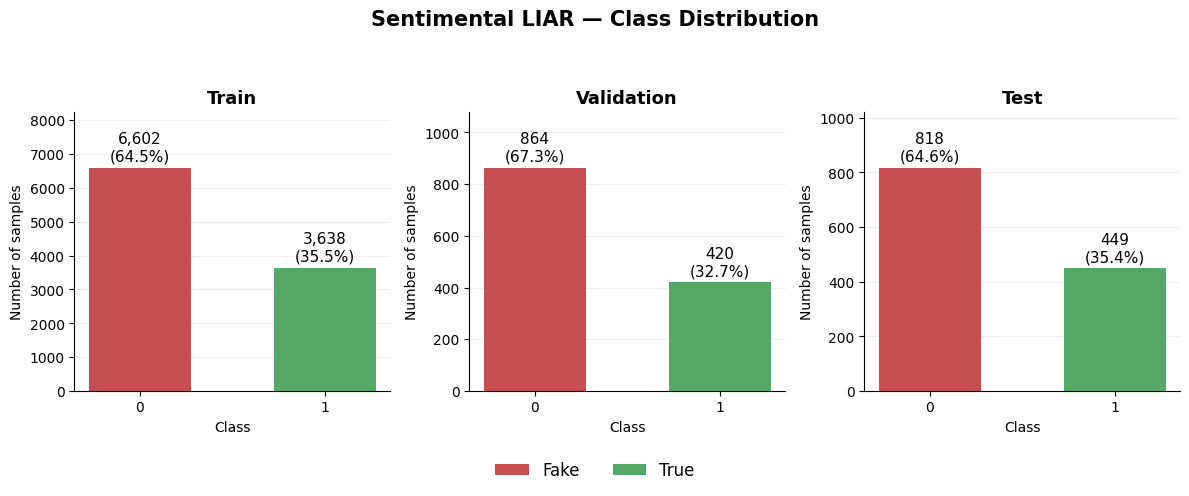

In [9]:

import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Cores por classe
CLASS_COLORS = {
    0: "#C44E52",  # Fake
    1: "#55A868"   # True
}

# Partições
groups = {
    "Train": splits["train"],
    "Validation": splits["validation"],
    "Test": splits["test"]
}

# Distribuição das classes
counts_table = pd.DataFrame({
    name: df["senti"].value_counts().reindex([0, 1], fill_value=0)
    for name, df in groups.items()
}).T

counts_table.columns = ["Fake", "True"]

print(counts_table)

# Figura única com três subplots
fig, axes = plt.subplots(1, 3, figsize=(12, 5))

for ax, (name, counts) in zip(axes, counts_table.iterrows()):

    bars = ax.bar(
        ["0", "1"],
        counts.values,
        color=[CLASS_COLORS[0], CLASS_COLORS[1]],
        width=0.55
    )

    for bar, count in zip(bars, counts):
        percentage = count / counts.sum() * 100

        ax.annotate(
            f"{count:,}\n({percentage:.1f}%)",
            (bar.get_x() + bar.get_width()/2, count),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            fontsize=11
        )

    ax.set_title(name, fontsize=13, fontweight="bold")
    ax.set_ylabel("Number of samples")
    ax.set_xlabel("Class")
    ax.set_ylim(0, max(counts) * 1.25)

    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# Legenda única
legend_elements = [
    Patch(facecolor=CLASS_COLORS[0], label="Fake"),
    Patch(facecolor=CLASS_COLORS[1], label="True")
]

fig.legend(
    handles=legend_elements,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=2,
    frameon=False,
    fontsize=12
)

fig.suptitle(
    "Sentimental LIAR — Class Distribution",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0.10, 1, 0.92])

fig.savefig(
    OUTPUT_DIR / "distribuicao_classes_senti.jpg",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)


## 6. PRÉ-PROCESSAMENTO TEXTUAL

In [7]:
# ============================================================
# Pré-processamento para nuvens de palavras
# Etapas do pré-processamento: tratamento de valores nulos, conversão para minúsculas, remoção de URLs, números, pontuação,
#caracteres especiais, stopwords e palavras com menos de 3 caracteres, seguido de tokenização e reconstrução do texto.
# ============================================================

def clean_text(text):
    """Normaliza o texto para visualização das palavras."""
    if pd.isna(text):
        return ""
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    words = [
        word
        for word in text.split()
        if len(word) > 2 and word not in STOPWORDS
    ]
    return " ".join(words)
for df in splits.values():
    df["clean_text"] = df["statement"].map(clean_text)
df_senti = pd.concat(splits.values(), ignore_index=True)

## 7. NUVENS DE PALAVRAS POR CLASSE E PARTIÇÃO

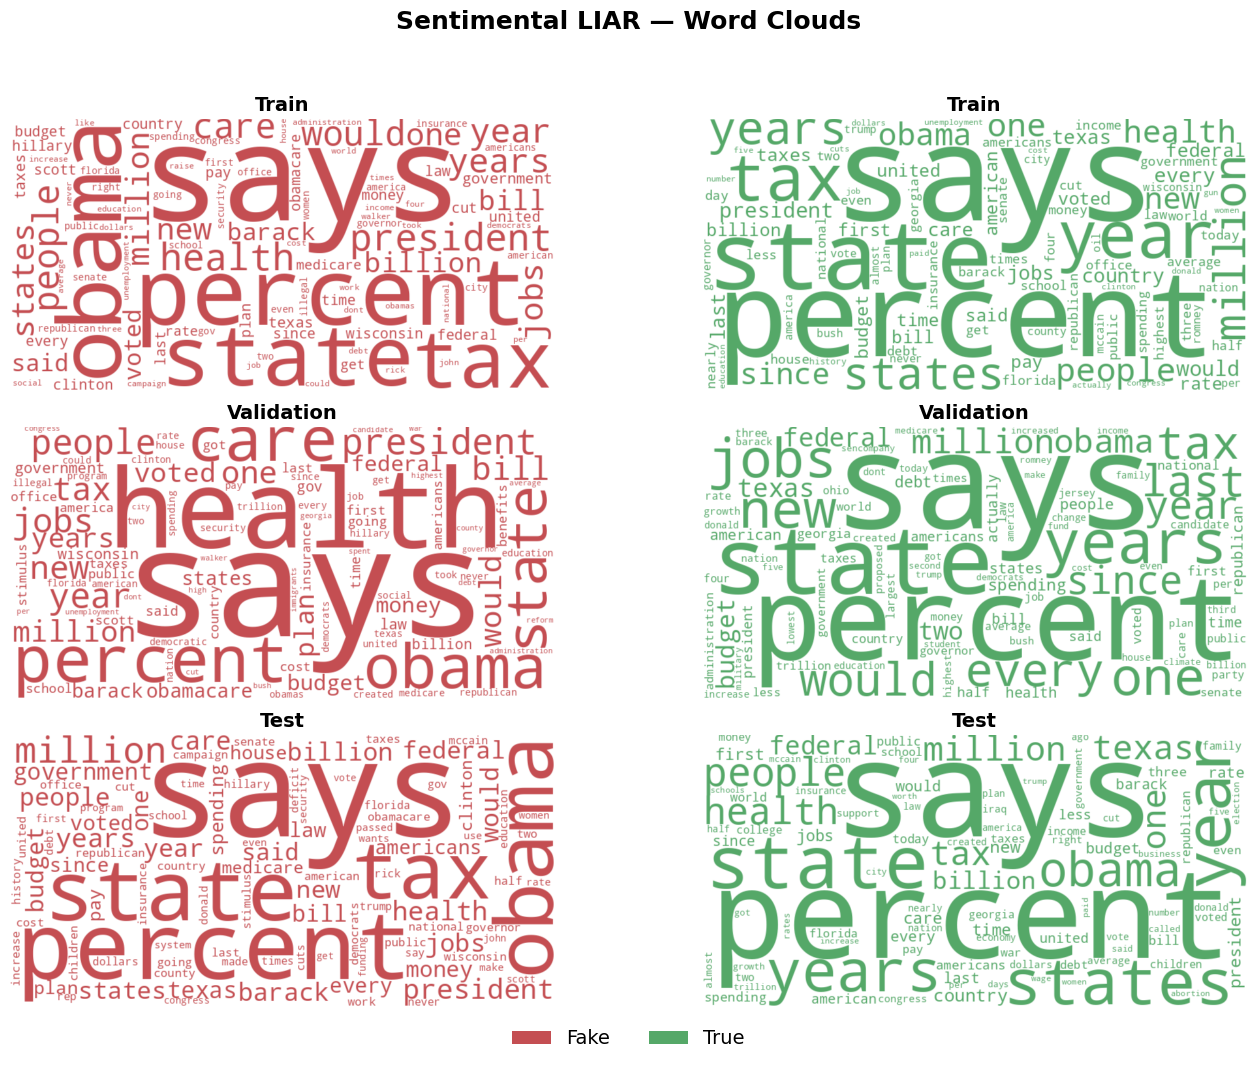

In [10]:

# ============================================================
# 7. NUVENS DE PALAVRAS POR CLASSE E PARTIÇÃO
# ============================================================

from collections import Counter
from wordcloud import WordCloud
from matplotlib.patches import Patch
import matplotlib.pyplot as plt

CLASS_COLORS = {
    0: "#C44E52",  # Fake
    1: "#55A868"   # True
}

def draw_cloud(ax, df, class_id, max_words=100):

    texts = df.loc[df["senti"] == class_id, "clean_text"]

    frequencies = Counter(
        word for text in texts for word in text.split()
    )

    color = CLASS_COLORS[class_id]

    if frequencies:
        cloud = WordCloud(
            width=800,
            height=400,
            background_color="white",
            max_words=max_words,
            random_state=SEED,
            collocations=False,
            color_func=lambda *args, **kwargs: color
        ).generate_from_frequencies(frequencies)

        ax.imshow(cloud, interpolation="bilinear")

    else:
        ax.text(
            0.5, 0.5, "No words",
            ha="center", va="center"
        )

    ax.axis("off")


# Partições
groups = {
    "Train": splits["train"],
    "Validation": splits["validation"],
    "Test": splits["test"]
}

# Figura única: 3 linhas e 2 colunas
fig, axes = plt.subplots(3, 2, figsize=(14, 11))

for row, (name, df) in enumerate(groups.items()):

    for class_id in range(2):

        ax = axes[row, class_id]

        draw_cloud(ax, df, class_id)

        ax.set_title(
            name,
            fontsize=14,
            fontweight="bold"
        )

# Legenda única ao final
legend_elements = [
    Patch(facecolor=CLASS_COLORS[0], label="Fake"),
    Patch(facecolor=CLASS_COLORS[1], label="True")
]

fig.legend(
    handles=legend_elements,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.02),
    ncol=2,
    frameon=False,
    fontsize=14
)

fig.suptitle(
    "Sentimental LIAR — Word Clouds",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0.06, 1, 0.95])

# Salvar figura
fig.savefig(
    OUTPUT_DIR / "wordcloud_senti_particoes.jpg",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)
